# NPC DSC 2026: Bird Sound Classification, Preprocessing Pipeline

Run this **after `01_EDA.ipynb`**: every choice here is backed by a finding there (see the EDA summary table).

This notebook runs every preprocessing script in order and shows what each step produced.
The logic lives in `scripts/` and `src/`. The notebook only runs those scripts and visualises their outputs, so every step can be explained and reproduced on its own.

**Task.** Classify short recordings as *Bondol Jawa*, *Cendrawasih* or *Kutilang*, or `Unknown` for species not seen in training. Test recordings contain rain, wind, insects and other background noise.

**Main constraint we found in the data.** Every `source_group` (an original recording source) contains **only one species**. A model can therefore score well by recognising the *recording* (microphone, background, level) instead of the *bird*. We treat that as a failure, not a shortcut. Every step below is designed so the model has to learn the bird call itself.

| Step | Script | What it does | Why (source) |
|---|---|---|---|
| 1 | `01_inventory.py` | File headers, class and group counts, train-vs-test check, stereo check | Know the data before changing it |
| 2 | `02_cache_audio.py` | FLAC 48 kHz stereo → mono 32 kHz `.npy` | BirdCLEF / Perch standard rate; decode once |
| 3 | `03_make_folds.py` | `StratifiedGroupKFold` on `source_group` | Validate on *unseen recordings* (Stowell 2022) |
| 4 | `04_activity_and_noise.py` | Activity curve per clip, plus a bank of call-free noise segments | Crops that contain the bird (BirdCLEF 2024 1st place); cross-group noise mixing (Lasseck 2018) |
| 5 | `05_compare_frontends.py` | Log-mel vs PCEN, with and without per-clip normalisation; augmentation ablation | PCEN for field recordings (Lostanlen et al. 2019) |

Every parameter (sample rate, mel settings, PCEN constants and so on) is in `src/config.py`.

In [1]:
import subprocess, sys, warnings
from pathlib import Path
warnings.filterwarnings("ignore", message="IProgress not found")

PIPELINE = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p/"src").is_dir()), Path.cwd())
assert (PIPELINE / "src").exists(), "run from inside the DSC_Pipeline tree"
sys.path.insert(0, str(PIPELINE))

import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Audio, display

from src import config as C, features as F, augment as A
from src.dataset import load_audio, load_activity, load_train_table, BirdWindowDataset

# Class colours: fixed order, colour-blind-checked categorical palette
CLASS_COLOR = {"Bondol Jawa": "#2a78d6", "Cendrawasih": "#eb6834", "Kutilang": "#1baf7a"}
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "axes.titleweight": "bold"})
pd.set_option("display.width", 160)

def run(script, *args):
    # Run one pipeline script with this notebook's Python, streaming its output
    _STAGE = {
    "00_eda_features.py":"stages/01_eda","01_extract_features.py":"stages/01_eda",
    "02_analyze.py":"stages/01_eda","03_plots.py":"stages/01_eda","04_report.py":"stages/01_eda",
    "01_inventory.py":"stages/02_preprocessing","02_cache_audio.py":"stages/02_preprocessing",
    "03_make_folds.py":"stages/02_preprocessing","04_activity_and_noise.py":"stages/02_preprocessing",
    "05_compare_frontends.py":"stages/02_preprocessing",
    "06_train.py":"stages/03_modeling","07_tune_unknown.py":"stages/03_modeling","08_infer.py":"stages/03_modeling",
}
    cmd = [sys.executable, script, *map(str, args)]
    print("$", " ".join(cmd[1:]), flush=True)
    p = subprocess.Popen(cmd, cwd=PIPELINE / _STAGE.get(script, "stages"), stdout=subprocess.PIPE,
                         stderr=subprocess.STDOUT, text=True)
    for line in p.stdout:
        print(line, end="")
    if p.wait() != 0:
        raise RuntimeError(f"{script} failed (exit code {p.returncode})")

print("data:", C.DATA_DIR, "| cache:", C.CACHE_DIR)

data: /sessions/rcw-01ywb44vcvg8tbc4czuzi2uf/mnt/NPC DSC 2026/kaggle | cache: /sessions/rcw-01ywb44vcvg8tbc4czuzi2uf/mnt/NPC DSC 2026/pipeline/cache


## Step 1: Inventory

Before changing anything, we check what is there and whether train and test look alike. Three questions matter:
1. **Class and group balance.** How many clips, and how many *independent recording sources*, per species?
2. **Train vs test.** Same sample rate, channels, durations? Differences here would mean a distribution shift.
3. **Stereo.** If the two channels were identical, averaging them to mono would lose nothing.

In [2]:
run("01_inventory.py")

$ 01_inventory.py


train clips: 1826   test clips: 814

class balance (clips / groups):
             clips  groups  median_dur
label                                 
Bondol Jawa   1124       7    9.888177
Cendrawasih     83       4   10.269729
Kutilang       619       4   10.336479

source groups: 15   groups with >1 species: 0
  -> every group is a single species: group identity == species in train.
     Validation MUST hold out whole groups, or recording conditions leak.

audio properties  train vs test:
  sr        train={48000: 1826}  test={48000: 814}
  channels  train={2: 1826}  test={2: 814}
  subtype   train={'PCM_24': 1826}  test={'PCM_24': 814}
  duration quantiles (s):
   train [ 5.27  7.08 10.03 12.94 14.9 ]
   test  [ 5.55  7.29 10.09 12.85 14.9 ]

stereo check on 80 clips: identical L/R = 0%, median L/R correlation = 0.889, median |level diff| = 0.10 dB


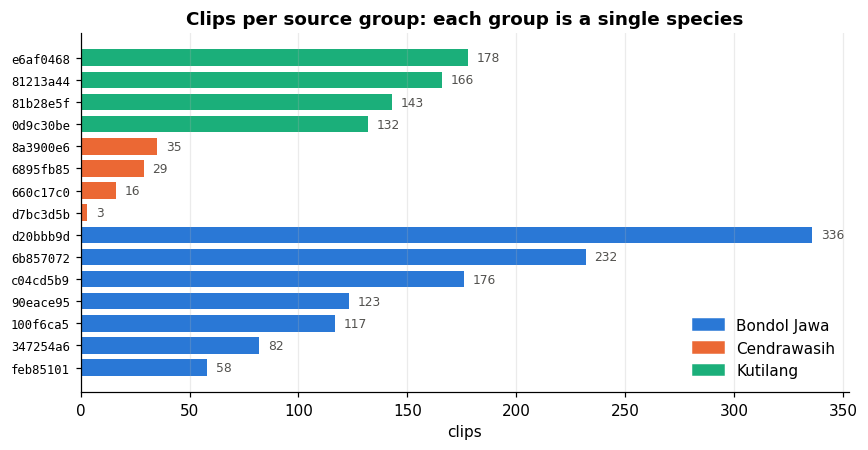

In [3]:
groups = pd.read_csv(C.OUT_DIR / "group_summary.csv").sort_values(["label", "clips"])
fig, ax = plt.subplots(figsize=(8, 4.2))
ax.barh(range(len(groups)), groups.clips, color=groups.label.map(CLASS_COLOR), height=0.75)
ax.set_yticks(range(len(groups)), [g[:8] for g in groups.source_group], fontsize=8, family="monospace")
for i, n in enumerate(groups.clips):
    ax.text(n + 4, i, str(n), va="center", fontsize=8, color="#52514e")
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=c) for c in CLASS_COLOR.values()],
          labels=list(CLASS_COLOR), loc="lower right", frameon=False)
ax.set_xlabel("clips"); ax.set_title("Clips per source group: each group is a single species")
ax.grid(axis="y", visible=False); plt.tight_layout(); plt.show()

**What this shows.**
- 15 source groups, **each containing exactly one species**. Cendrawasih has only 83 clips from 4 groups, and one of those groups has just 3 clips. In terms of independent recording conditions, that is very few examples.
- Train and test match on every header property: 48 kHz, stereo, 24-bit, durations of about 5–15 s with a median of about 10 s.
- The stereo channels are **not** identical (median L/R correlation about 0.89), but they are very similar in level. We average them to mono, which is the BirdCLEF standard. Keeping both channels is a possible later experiment.

## Step 2: Decode once, resample to 32 kHz mono

- **Mono:** the average of the left and right channels.
- **32 kHz:** an exact 2/3 polyphase resample from 48 kHz. It keeps every frequency up to 16 kHz, which covers the bird range. 32 kHz is the rate used by BirdCLEF solutions and by Google's Perch model.
- **Level is not changed here.** Whether to normalise loudness is a front-end choice that we test in step 5.
- Files are stored as float16 `.npy` (about 1.7 GB in total), so training never decodes FLAC again. Re-running the script skips files that are already cached.

The script also hashes every decoded clip to catch **exact duplicates** inside train and between train and test.

In [4]:
run("02_cache_audio.py", "--workers", 4)

$ 02_cache_audio.py --workers 4


  cached 250/2640


  cached 500/2640


  cached 750/2640


  cached 1000/2640


...

  cached 1750/2640


  cached 2000/2640


  cached 2250/2640


  cached 2500/2640
  cached 2640/2640



exact duplicate audio: 0 files in 0 sets (0 sets involve train, 0 sets shared between train and test)

level (RMS dBFS) by split:
       mean  std   min   max
split                       
test  -21.4  2.8 -33.2 -13.9
train -21.4  2.9 -35.3 -14.4


No exact duplicates were found. Average loudness is the same in train and test (about −21.4 dBFS), so there is no level shift between the splits.

## Step 3: Group-aware validation folds

Because group equals species, a random train/validation split lets recordings from the *same source* appear on both sides, which rewards memorising the recording. We use `StratifiedGroupKFold`: whole groups are held out, and each fold still validates all three species. The script tries 300 seeds and keeps the most class-balanced split.

Single folds contain very few Cendrawasih clips, so **all metrics are computed on pooled out-of-fold predictions** (each clip is predicted once by the model that did not train on its group).

In [5]:
run("03_make_folds.py")

$ 03_make_folds.py


chosen seed 19; validation clips per fold x class:
label  Bondol Jawa  Cendrawasih  Kutilang   All
fold                                           
0              232           35       143   410
1              293           16       178   487
2              394           29       132   555
3              205            3       166   374
All           1124           83       619  1826

validation groups per fold x class:
label  Bondol Jawa  Cendrawasih  Kutilang
fold                                     
0                1            1         1
1                2            1         1
2                2            1         1
3                2            1         1

check passed: no source_group appears in more than one fold
note: metrics should be computed on pooled out-of-fold predictions; single folds have very few Cendrawasih clips.


## Step 4: Where are the calls? Where is just background?

**Activity curve.** For each mel band between 0.5 and 12 kHz, we subtract the band's median level (its noise floor) and average the excess across bands. Steady noise such as insects, hum or steady rain stays near zero, and bird calls produce peaks.

It is used for two things:
1. **Choosing training crops.** A random 5 s crop of a 10 s clip can land on silence and still carry the species label. Crops are sampled where the curve is high (with a 20% chance of a fully random crop, to keep variety). This follows the BirdCLEF 2024 winner, who removed training chunks that contained no call.
2. **A noise bank.** Quiet stretches of at least 1 s (the bottom 30% of the curve) are cut from training clips. During training they are **mixed into clips from other source groups**, so a background sound can no longer identify a species. This follows Lasseck (BirdCLEF 2018), where adding background noise gave the largest augmentation gain.

In [6]:
run("04_activity_and_noise.py")

$ 04_activity_and_noise.py


activity summary by class (train) and test:
             activity_ratio  peak_window_score  snr_est_db
label                                                     
(test)                0.053              2.031      10.889
Bondol Jawa           0.023              1.850      10.736
Cendrawasih           0.073              2.083       8.210
Kutilang              0.039              2.173      11.532

noise bank: 762 segments, 18.1 min total, from 694 clips in 15 groups
             segments  minutes
label                         
Bondol Jawa       533     12.9
Cendrawasih        44      1.1
Kutilang          185      4.2


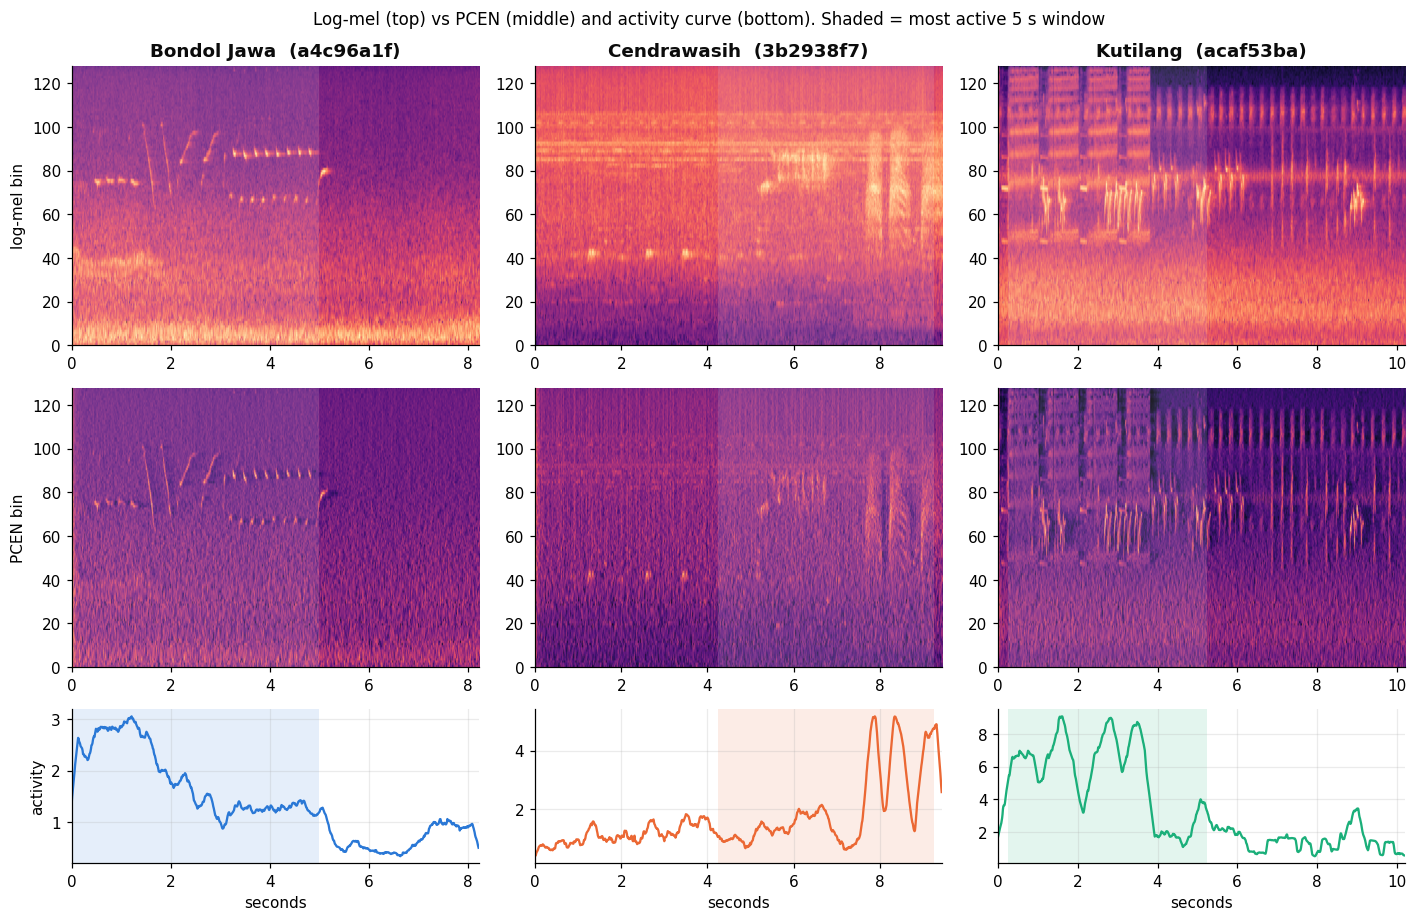

Bondol Jawa - full clip, then one noise-bank segment cut from it


Cendrawasih - full clip, then one noise-bank segment cut from it


Kutilang - full clip, then one noise-bank segment cut from it


In [7]:
t = load_train_table()
act = pd.read_csv(C.OUT_DIR / "activity_summary.csv")
bank = pd.read_csv(C.OUT_DIR / "noise_bank.csv")
rng = np.random.default_rng(7)
examples = {lab: rng.choice(bank[bank.label == lab].file_id.unique()) for lab in C.CLASSES}

fig, axes = plt.subplots(3, 3, figsize=(13, 8.5), gridspec_kw={"height_ratios": [1, 1, 0.55]})
for j, (lab, fid) in enumerate(examples.items()):
    y, curve = load_audio("train", fid), load_activity(fid)
    sec = len(y) / C.SR
    lm, pc = F.logmel(y), F.pcen(y)
    axes[0, j].imshow(lm, origin="lower", aspect="auto", cmap="magma", extent=[0, sec, 0, C.N_MELS])
    axes[1, j].imshow(pc, origin="lower", aspect="auto", cmap="magma", extent=[0, sec, 0, C.N_MELS])
    tt = np.arange(len(curve)) * C.HOP / C.SR
    axes[2, j].plot(tt, curve, color=CLASS_COLOR[lab], lw=1.5)
    starts, scores = A.window_scores(curve, C.WIN)
    s = min(starts[np.argmax(scores)], max(len(y) - C.WIN, 0)) / C.SR
    for ax in axes[:, j]:
        ax.axvspan(s, s + C.WIN_SEC, color="#ffffff" if ax is not axes[2, j] else CLASS_COLOR[lab],
                   alpha=0.12, lw=0)
        ax.set_xlim(0, sec)
    axes[0, j].set_title(f"{lab}  ({fid[:8]})", color="#0b0b0b")
    axes[2, j].set_xlabel("seconds")
axes[0, 0].set_ylabel("log-mel bin"); axes[1, 0].set_ylabel("PCEN bin"); axes[2, 0].set_ylabel("activity")
for ax in axes[:2].ravel():
    ax.grid(False)
fig.suptitle("Log-mel (top) vs PCEN (middle) and activity curve (bottom). Shaded = most active 5 s window",
             fontsize=11)
plt.tight_layout(); plt.show()

for lab, fid in examples.items():
    print(lab, "- full clip, then one noise-bank segment cut from it")
    display(Audio(load_audio("train", fid), rate=C.SR))
    nf = bank[bank.file_id == fid].noise_file.iloc[0]
    display(Audio(np.load(C.NOISE_CACHE / nf).astype(np.float32), rate=C.SR))

**Things to check by eye and ear:** PCEN should make the calls stand out more cleanly than log-mel, because steady background bands are flattened. The shaded window should sit on calls. The noise segments should sound like background with no clear call. If you hear a clear call in a noise segment, lower `NOISE_QUANTILE` in `src/config.py` and re-run step 4.

**EDA follow-up: insect pulses.** EDA found a rhythmic, insect-like pulse noise in about 1/3 of clips of every class and of test. Two risks to check: (1) the activity curve could treat pulses as calls and steer crops toward them, and (2) the noise bank could miss pulse noise, because pulses leave few quiet gaps of 1 s or more.

In [8]:
pulse = pd.read_csv(C.OUT_DIR / "eda" / "clip_stats.csv")[["file_id", "split", "pulse_strength"]]
pulse["pulse"] = pd.cut(pulse.pulse_strength, [-1, 0.2, 0.5, 1.1], labels=["weak (<0.2)", "mid", "strong (>0.5)"])

def periodicity(c):
    c = c - c.mean(); ac = np.correlate(c, c, "full")[len(c) - 1:]; ac /= ac[0] + 1e-12
    return ac[30:200].max()

samp = pulse[pulse.split == "train"].sample(400, random_state=0)
samp["activity_curve_periodicity"] = [periodicity(load_activity(f).astype(float)) for f in samp.file_id]
display(samp.groupby("pulse", observed=True).activity_curve_periodicity.median().round(2).to_frame())

trp = pulse[pulse.split == "train"]
nb_src = bank.merge(trp, on="file_id")
print(f"strong-pulse share: all training clips {(trp.pulse_strength > 0.5).mean():.2f} | "
      f"noise-bank segments {(nb_src.pulse_strength > 0.5).mean():.2f}")

,activity_curve_periodicity
pulse,
weak (<0.2),0.45
mid,0.51
strong (>0.5),0.53


strong-pulse share: all training clips 0.34 | noise-bank segments 0.33


**Result.** The activity curve is somewhat more periodic in strong-pulse clips than in quiet ones (about 0.53 vs 0.45), so pulses do leak into it a little. But the pulses run through the whole clip, so they raise every candidate window by a similar amount and should not change which window wins much. The noise bank contains pulse noise in proportion (about 33% of segments vs 34% of clips). **No change for now.** We will listen to some selected crops from strong-pulse clips during the model step.

## What the training data loader will produce (augmentation preview)

`BirdWindowDataset` (in `src/dataset.py`) is what the model will train on. It produces one 5 s window per clip per epoch:
- an activity-weighted crop,
- background mixed in from **other** source groups, at a random 3–20 dB SNR,
- a mild random EQ of ±4 dB (simulating different microphones; kept small because frequency cues identify species),
- random gain and SpecAugment masking.

It deliberately leaves out **pitch shift and time stretch**, because they change species-defining cues (Stowell 2022; BirdCLEF 2024 teams disabled them). **Mixup** is available but off by default, because it hurt the BirdCLEF 2024 winner.

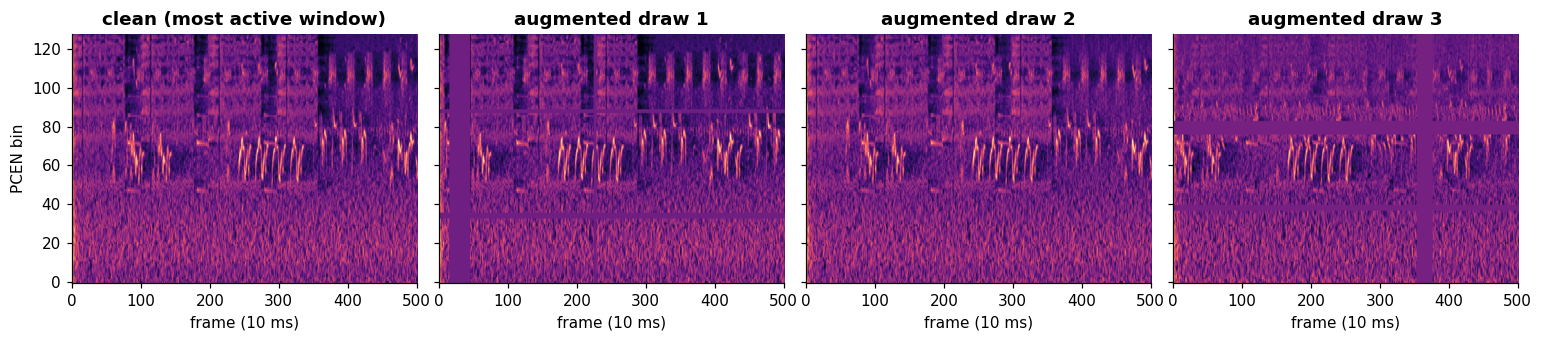

Same crop: clean, then with cross-group background mixed in


In [9]:
fid = examples["Kutilang"]
row = t[t.file_id == fid]
noise_bank = A.NoiseBank.load()
clean_ds = BirdWindowDataset(row, frontend="pcen_norm", train=False)
aug_ds = BirdWindowDataset(row, frontend="pcen_norm", train=True, noise_bank=noise_bank, seed=3)

fig, axes = plt.subplots(1, 4, figsize=(14, 3.2), sharey=True)
axes[0].imshow(clean_ds[0][0][0], origin="lower", aspect="auto", cmap="magma")
axes[0].set_title("clean (most active window)")
for k in range(1, 4):
    axes[k].imshow(aug_ds[0][0][0], origin="lower", aspect="auto", cmap="magma")
    axes[k].set_title(f"augmented draw {k}")
for ax in axes:
    ax.grid(False); ax.set_xlabel("frame (10 ms)")
axes[0].set_ylabel("PCEN bin"); plt.tight_layout(); plt.show()

rng = np.random.default_rng(11)
y, curve = load_audio("train", fid), load_activity(fid)
w = A.choose_crop(y, curve, C.WIN, rng)
print("Same crop: clean, then with cross-group background mixed in")
display(Audio(w, rate=C.SR))
display(Audio(A.augment_wave(w, row.source_group.iloc[0], rng, noise_bank,
                             A.AugConfig(p_noise=1.0, p_eq=0, p_gain=0)), rate=C.SR))

## Step 5: Which preprocessing is best, measured honestly?

A quick, transparent probe (not the final model): each clip is summarised as the per-band mean and standard deviation of its spectrogram (256 numbers), and a class-balanced logistic regression is evaluated with the group folds from step 3. Three diagnostics:

- **group-CV macro-F1.** The honest score. This is what we optimise.
- **random-CV macro-F1.** The same model on a random split. The gap shows how much a careless split would flatter us.
- **group-ID probe.** Within each species, how accurately the features identify *which recording group* a clip came from (balanced accuracy, with chance level shown). Lower means less microphone or background information in the features.

Augmentation ablation on `pcen_norm`: `crop` (activity-weighted crops only), then `+noise` (cross-group mixing), then `full` (+EQ and gain). The noise bank for each fold uses **only training-fold groups**, so no validation recording leaks into training.

Running it takes about 5 minutes. If `outputs/frontend_comparison.csv` already exists, it is reused unless `RERUN_STEP5 = True`.

In [10]:
RERUN_STEP5 = False
if RERUN_STEP5 or not (C.OUT_DIR / "frontend_comparison.csv").exists():
    run("05_compare_frontends.py")
res = pd.read_csv(C.OUT_DIR / "frontend_comparison.csv")
res.round(3)

,variant,augmented,accuracy,macro_f1,recall_Bondol,recall_Cendrawasih,recall_Kutilang,random_cv_macro_f1,group_id_probe,group_id_chance
0,logmel,False,0.911,0.803,0.928,0.663,0.914,0.858,0.672,0.242
1,logmel_norm,False,0.912,0.811,0.924,0.675,0.921,0.843,0.663,0.242
2,pcen,False,0.921,0.819,0.919,0.735,0.950,0.855,0.682,0.242
3,pcen_norm,False,0.923,0.835,0.921,0.771,0.948,0.847,0.664,0.242
4,pcen_norm+crop,True,0.916,0.819,0.918,0.699,0.940,NaN,NaN,NaN
5,pcen_norm+crop+noise,True,0.917,0.812,0.921,0.699,0.940,NaN,NaN,NaN
6,pcen_norm+full,True,0.914,0.813,0.916,0.735,0.934,NaN,NaN,NaN


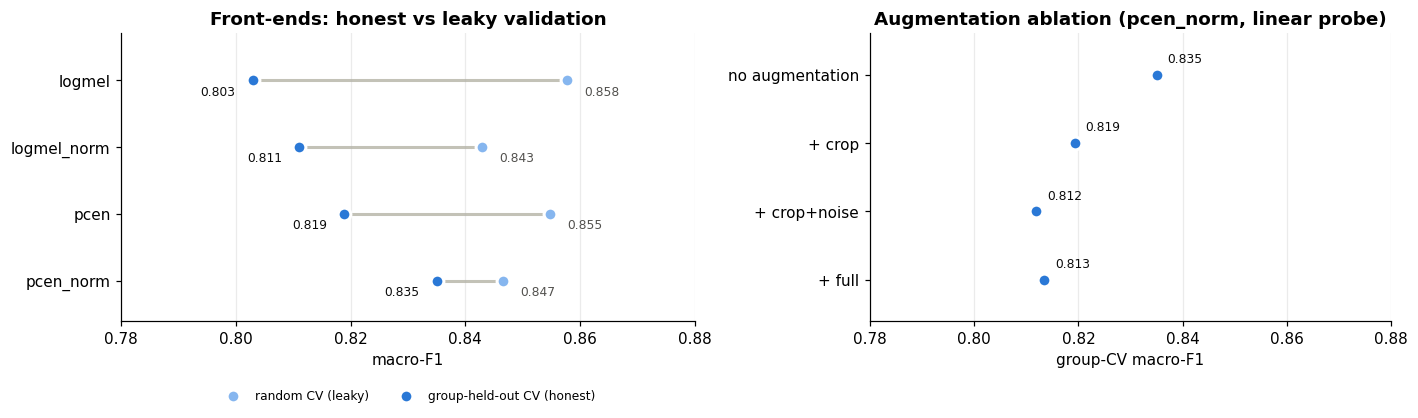

In [11]:
clean = res[~res.augmented].reset_index(drop=True)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.0), gridspec_kw={"width_ratios": [1.1, 1]})
ax = axes[0]
for i, r in clean.iterrows():
    ax.plot([r.macro_f1, r.random_cv_macro_f1], [i, i], color="#c3c2b7", lw=2, zorder=1)
ax.scatter(clean.random_cv_macro_f1, clean.index, s=70, color="#86b6ef", zorder=2,
           edgecolor="white", linewidth=2, label="random CV (leaky)")
ax.scatter(clean.macro_f1, clean.index, s=70, color="#2a78d6", zorder=3,
           edgecolor="white", linewidth=2, label="group-held-out CV (honest)")
for i, r in clean.iterrows():
    ax.text(r.macro_f1 - 0.003, i + 0.22, f"{r.macro_f1:.3f}", ha="right", fontsize=8, color="#0b0b0b")
    ax.text(r.random_cv_macro_f1 + 0.003, i + 0.22, f"{r.random_cv_macro_f1:.3f}", fontsize=8, color="#52514e")
ax.set_yticks(clean.index, clean.variant); ax.invert_yaxis(); ax.set_ylim(len(clean) - 0.4, -0.7)
ax.set_xlim(0.78, 0.88); ax.set_xlabel("macro-F1"); ax.grid(axis="y", visible=False)
ax.set_title("Front-ends: honest vs leaky validation")
ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=2, fontsize=8)

abl = res[res.variant.str.startswith("pcen_norm")].reset_index(drop=True)
ax = axes[1]
ax.scatter(abl.macro_f1, abl.index, s=70, color="#2a78d6", edgecolor="white", linewidth=2, zorder=3)
for i, v in enumerate(abl.macro_f1):
    ax.text(v + 0.002, i - 0.18, f"{v:.3f}", fontsize=8, color="#0b0b0b")
ax.set_yticks(abl.index, ["no augmentation" if v == "pcen_norm" else v.replace("pcen_norm+", "+ ")
                          for v in abl.variant])
ax.invert_yaxis(); ax.set_ylim(len(abl) - 0.4, -0.6); ax.set_xlim(0.78, 0.88)
ax.set_xlabel("group-CV macro-F1"); ax.grid(axis="y", visible=False)
ax.set_title("Augmentation ablation (pcen_norm, linear probe)")
plt.tight_layout(); plt.show()

## Findings and decisions

Numbers are from this run. Seeds are fixed, so re-running gives the same values.

1. **Use PCEN + per-clip normalisation (`pcen_norm`) as the default front-end.** It has the best honest score (macro-F1 **0.835** vs **0.803** for plain log-mel) and the largest gain on the hardest class (Cendrawasih recall **0.77** vs **0.66**). It also has the smallest honest-vs-leaky gap (0.835 vs 0.847), meaning it depends least on recording-specific cues.
2. **Group-held-out validation is necessary.** A random split overstates every variant by up to about 5 points of macro-F1 (log-mel: 0.858 vs 0.803).
3. **The recording fingerprint is still strong.** Within a species, the features identify the source group with about 0.66 balanced accuracy against a chance level of 0.24, whatever the front-end. This matches Lostanlen et al.: PCEN reduces stationary noise but does not remove differences between sensors. Reducing this is the job of training-time augmentation and of a model that learns call shapes, not of the front-end.
4. **Augmentation did not help this linear probe** (crop 0.819, +noise 0.812, full 0.813 vs 0.835 without). We are not drawing a final conclusion from this. A logistic regression on averaged band statistics cannot learn from varied examples the way a CNN can, and the Cendrawasih differences come down to about 6 of 83 clips. **Decision:** keep the augmentation switches in the loader and re-run this same ablation with the real model.
5. **Unchanged from the research review:** 32 kHz mono, 5 s windows with loop padding, sliding 2.5 s-stride windows at test time, no heavy denoising, no pitch shift or time stretch, mixup off by default.

**Next:** model step. Pretrained bird embeddings (Perch / BirdNET) and/or a CNN on `pcen_norm` windows, using the same folds, then the `Unknown` rejection strategy tuned with leave-one-class-out validation.

### References
- Lostanlen, V. et al. (2019). *Robust sound event detection in bioacoustic sensor networks.* PLoS ONE. (PCEN)
- Stowell, D. (2022). *Computational bioacoustics with deep learning: a review and roadmap.* PeerJ.
- Lasseck, M. (2018). BirdCLEF 2018 working notes, CEUR-WS Vol-2125.
- BirdCLEF 2024 1st place solution write-up; Porwal, A. (2024), CLEF working notes.
- *Generalization in birdsong classification: impact of transfer learning methods and dataset characteristics* (2024). arXiv:2409.15383.